# DESIGN AND IMPLEMENTATION OF A GENERATIVE AI-BASED PERSONALIZED FEEDBACK SYSTEM FOR ACADEMIC STAFF STRESS-LEVEL ASSESSMENT

**Researcher:** OKON, GOODNEWS ASUQUO (Reg. No: `AK22/PHS/CSC/078`)  
**Department:** Computer Science, Faculty of Physical Sciences  
**Institution:** Akwa Ibom State University (AKSU), Ikot Akpaden, Nigeria  

---

### Project Overview & Pipeline
1. **Dataset Loading & Pre-processing**: Loading Sheets 3, 4, and 5 with standardized feature harmonization across **$N=110$ academic staff records**.
2. **Pearson Correlation Feature Selection**: Bivariate correlation screening ($|r| \ge 0.30, p < 0.01$) identifying **15 high-contribution stress indicators**.
3. **Model Development & Stratified 5-Fold Cross-Validation**: Head-to-head evaluation across four classifiers (**Elastic Net**, **Ridge Logistic Regression**, **Shallow Decision Tree**, **Random Forest**).
4. **Performance Parameters & Graphical Evaluations**: Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrices, and ROC Curves.
5. **Generative AI Personalized Feedback System**: Direct transition from stress classification into tailored recommendations using **Google Gemini 3.8 Flash**.

## 1. Environment Setup & Schema Definitions
Import required scientific libraries and configure questionnaire indicator mappings.

In [1]:
import json
import os
import warnings
from pathlib import Path
from typing import Any, Dict, List

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

from stress_system_core import (
    ALL_23_FEATURE_COLS,
    COLUMN_RENAME_MAP,
    EXCEL_PATH,
    FEATURE_DOMAINS,
    FEATURE_LABELS,
    FIGURES_DIR,
    MODELS_DIR,
    OUTPUT_DIR,
    PEARSON_15_FEATURES,
    TABLES_DIR,
    VALUE_DECODERS,
    load_all_project_sheets,
    evaluate_models_stratified_5fold,
    generate_personalized_feedback,
)

DATASET_PATH = TABLES_DIR / 'academic_staff_stress_dataset.csv'
warnings.filterwarnings('ignore')
print(f'Setup complete. Active feature subset: {len(PEARSON_15_FEATURES)} Pearson features.')

Setup complete. Active feature subset: 15 Pearson features.


## 2. Multi-Sheet Data Loading & Cohort Schema Overview
Load **Sheet 3 (`digitized`)**, **Sheet 4 (`transpose`)**, and **Sheet 5 (`attributes responses`)** from `my dataset google form_new.xlsx`. The academic staff cohort comprises **$N=110$ records** (68 Low Stress, 42 High Stress) evaluated against the 40-point institutional stress cutoff.

In [2]:
sheets = load_all_project_sheets(EXCEL_PATH)
df3 = sheets['sheet3_digitized']
df4 = sheets['sheet4_transpose']
df5 = sheets['sheet5_attributes']

df_cohort = pd.read_csv(DATASET_PATH)
print(f'Academic Staff Dataset shape: {df_cohort.shape} (N=110: 68 Low Stress, 42 High Stress)')
print(f'Sheet 4 (transpose) shape : {df4.shape}')
print(f'Sheet 5 (attributes) shape: {df5.shape}')
print(f'Missing / Null values     : {df_cohort.isnull().sum().sum()}')
display(df_cohort.head(8))

Academic Staff Dataset shape: (110, 26) (N=110: 68 Low Stress, 42 High Stress)
Sheet 4 (transpose) shape : (25, 76)
Sheet 5 (attributes) shape: (23, 6)
Missing / Null values     : 0


,staff_code,age,gender,educational_qualification,academic_rank,teaching_experience,teaching_workload,research_responsibilities,administrative_responsibilities,exam_supervision_marking,teaching_hours,genai_tool_frequency,genai_research_teaching_usefulness,genai_admin_use,smoking,alcohol_consumption,alcohol_frequency,physical_exercise,physical_exercise_frequency,break_frequency,health_problems_affect_coping,feedback_preference,feedback_frequency,genai_system_trust,total_score,stress_class
0,A001,2,1,0,6,4,0,0,1,2,0,0,0,0,1,0,0,1,1,0,2,0,0,0,21,0
1,A002,1,2,1,2,2,2,1,2,2,0,0,0,0,0,0,2,0,2,0,1,0,0,0,20,0
2,A003,1,2,0,1,0,1,1,2,2,0,0,0,0,0,0,1,1,1,0,1,0,0,0,14,0
3,A004,1,2,1,1,0,2,3,3,3,0,0,0,0,0,0,0,1,3,0,0,0,0,0,20,0
4,A005,4,2,0,6,4,4,4,4,3,0,0,0,0,0,0,0,1,3,0,1,0,0,0,36,0
5,A006,1,2,1,1,0,3,1,1,2,0,0,0,0,0,0,0,1,1,0,1,0,0,0,15,0
6,A007,3,2,0,4,3,3,3,3,3,0,0,0,0,0,0,1,1,1,0,0,0,0,0,27,0
7,A008,3,2,0,3,0,2,2,3,1,3,0,0,0,0,0,1,1,1,0,0,0,0,0,22,0


## 3. Exploratory Data Analysis & Graphical Representations
Visualizing stress class distributions, composite scores, cumulative domain burdens, and respondent profile heatmaps.

### Graphical Representation: Class and Score Distributions (Figure 1)
Academic staff stress class distribution and composite score separation across the 40-point institutional threshold ($N=110$).

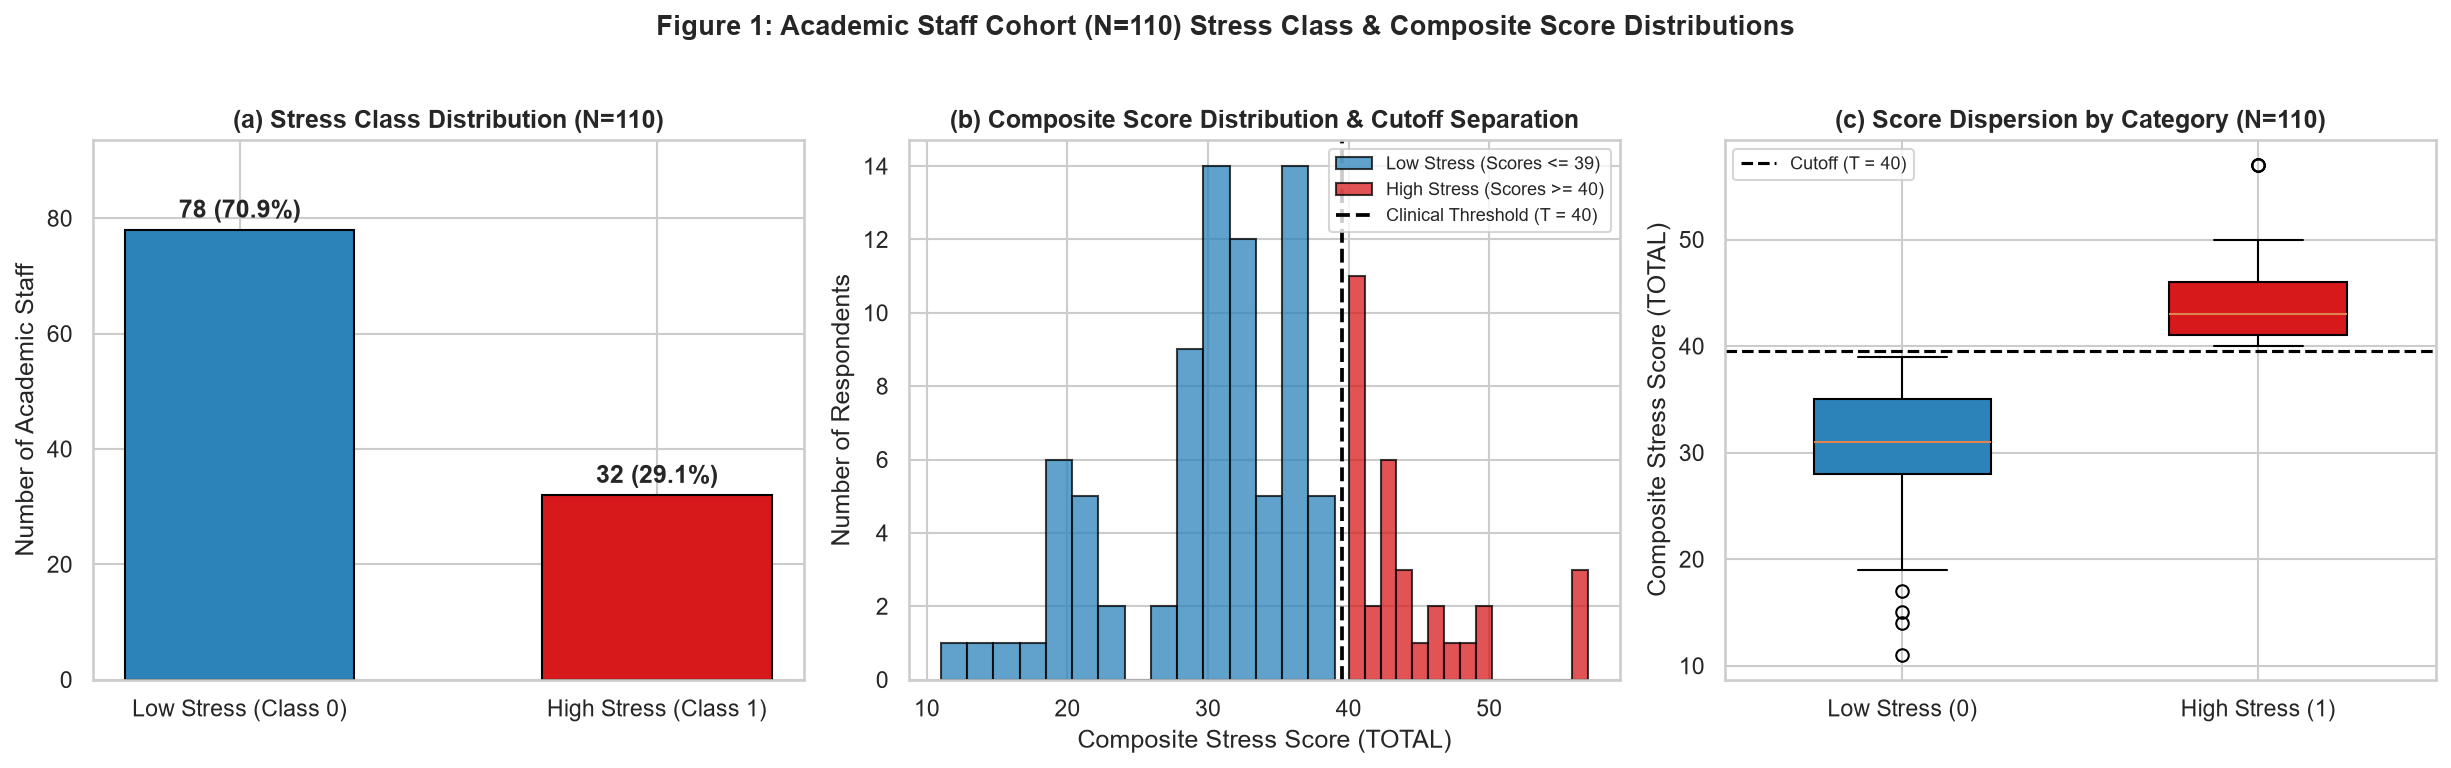

In [3]:
# Figure 1: Class Distribution & Composite Score Separation
display(Image(filename=str(FIGURES_DIR / 'fig1_class_and_score_distribution.png')))

### Graphical Representation: Cumulative Indicator Burden by Domain (Figure 2)
Cumulative score sums across all academic staff respondents from Sheet 5 (`attributes responses`), grouped by theoretical domain.

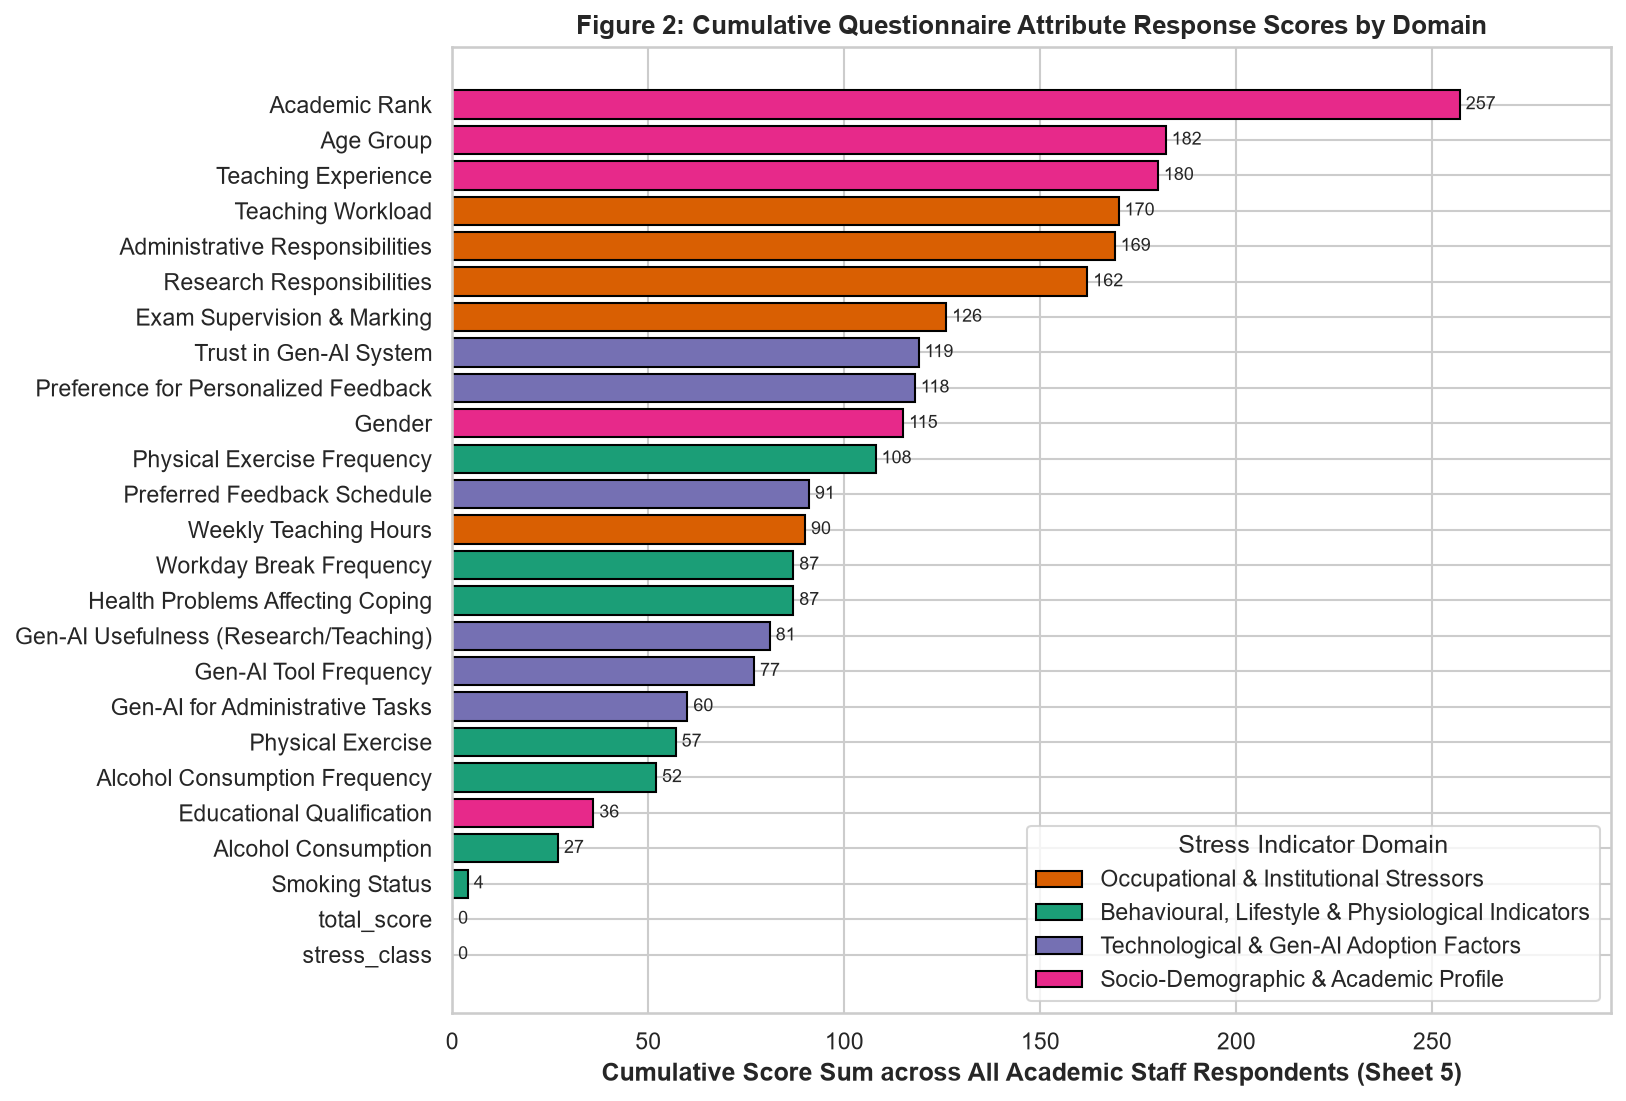

In [4]:
# Figure 2: Cumulative Indicator Responses by Domain (Sheet 5)
display(Image(filename=str(FIGURES_DIR / 'fig2_sheet5_attribute_responses.png')))

### Graphical Representation: Respondent Profiles & Correlation Heatmap (Figures 3 & 4)
- **Figure 3**: Transposed profile heatmap (Sheet 4) ordered by stress class.
- **Figure 4**: Pearson correlation matrix across indicators for multicollinearity screening.

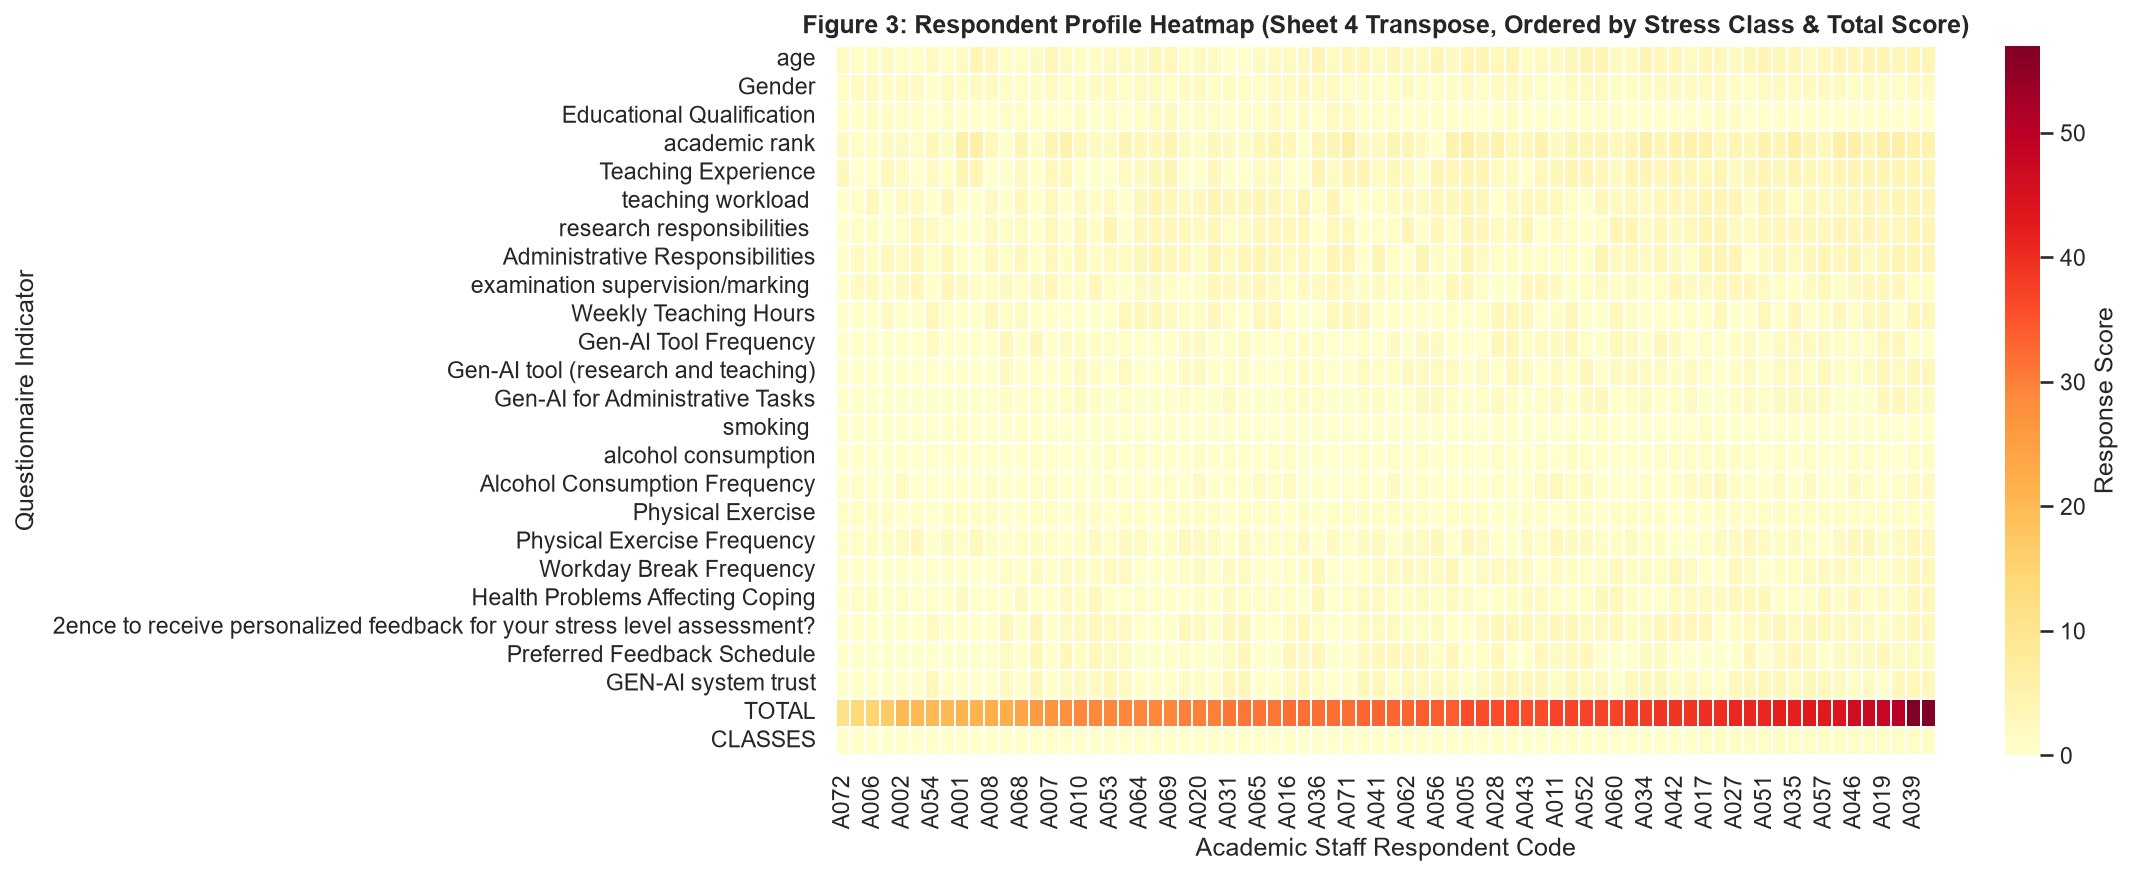

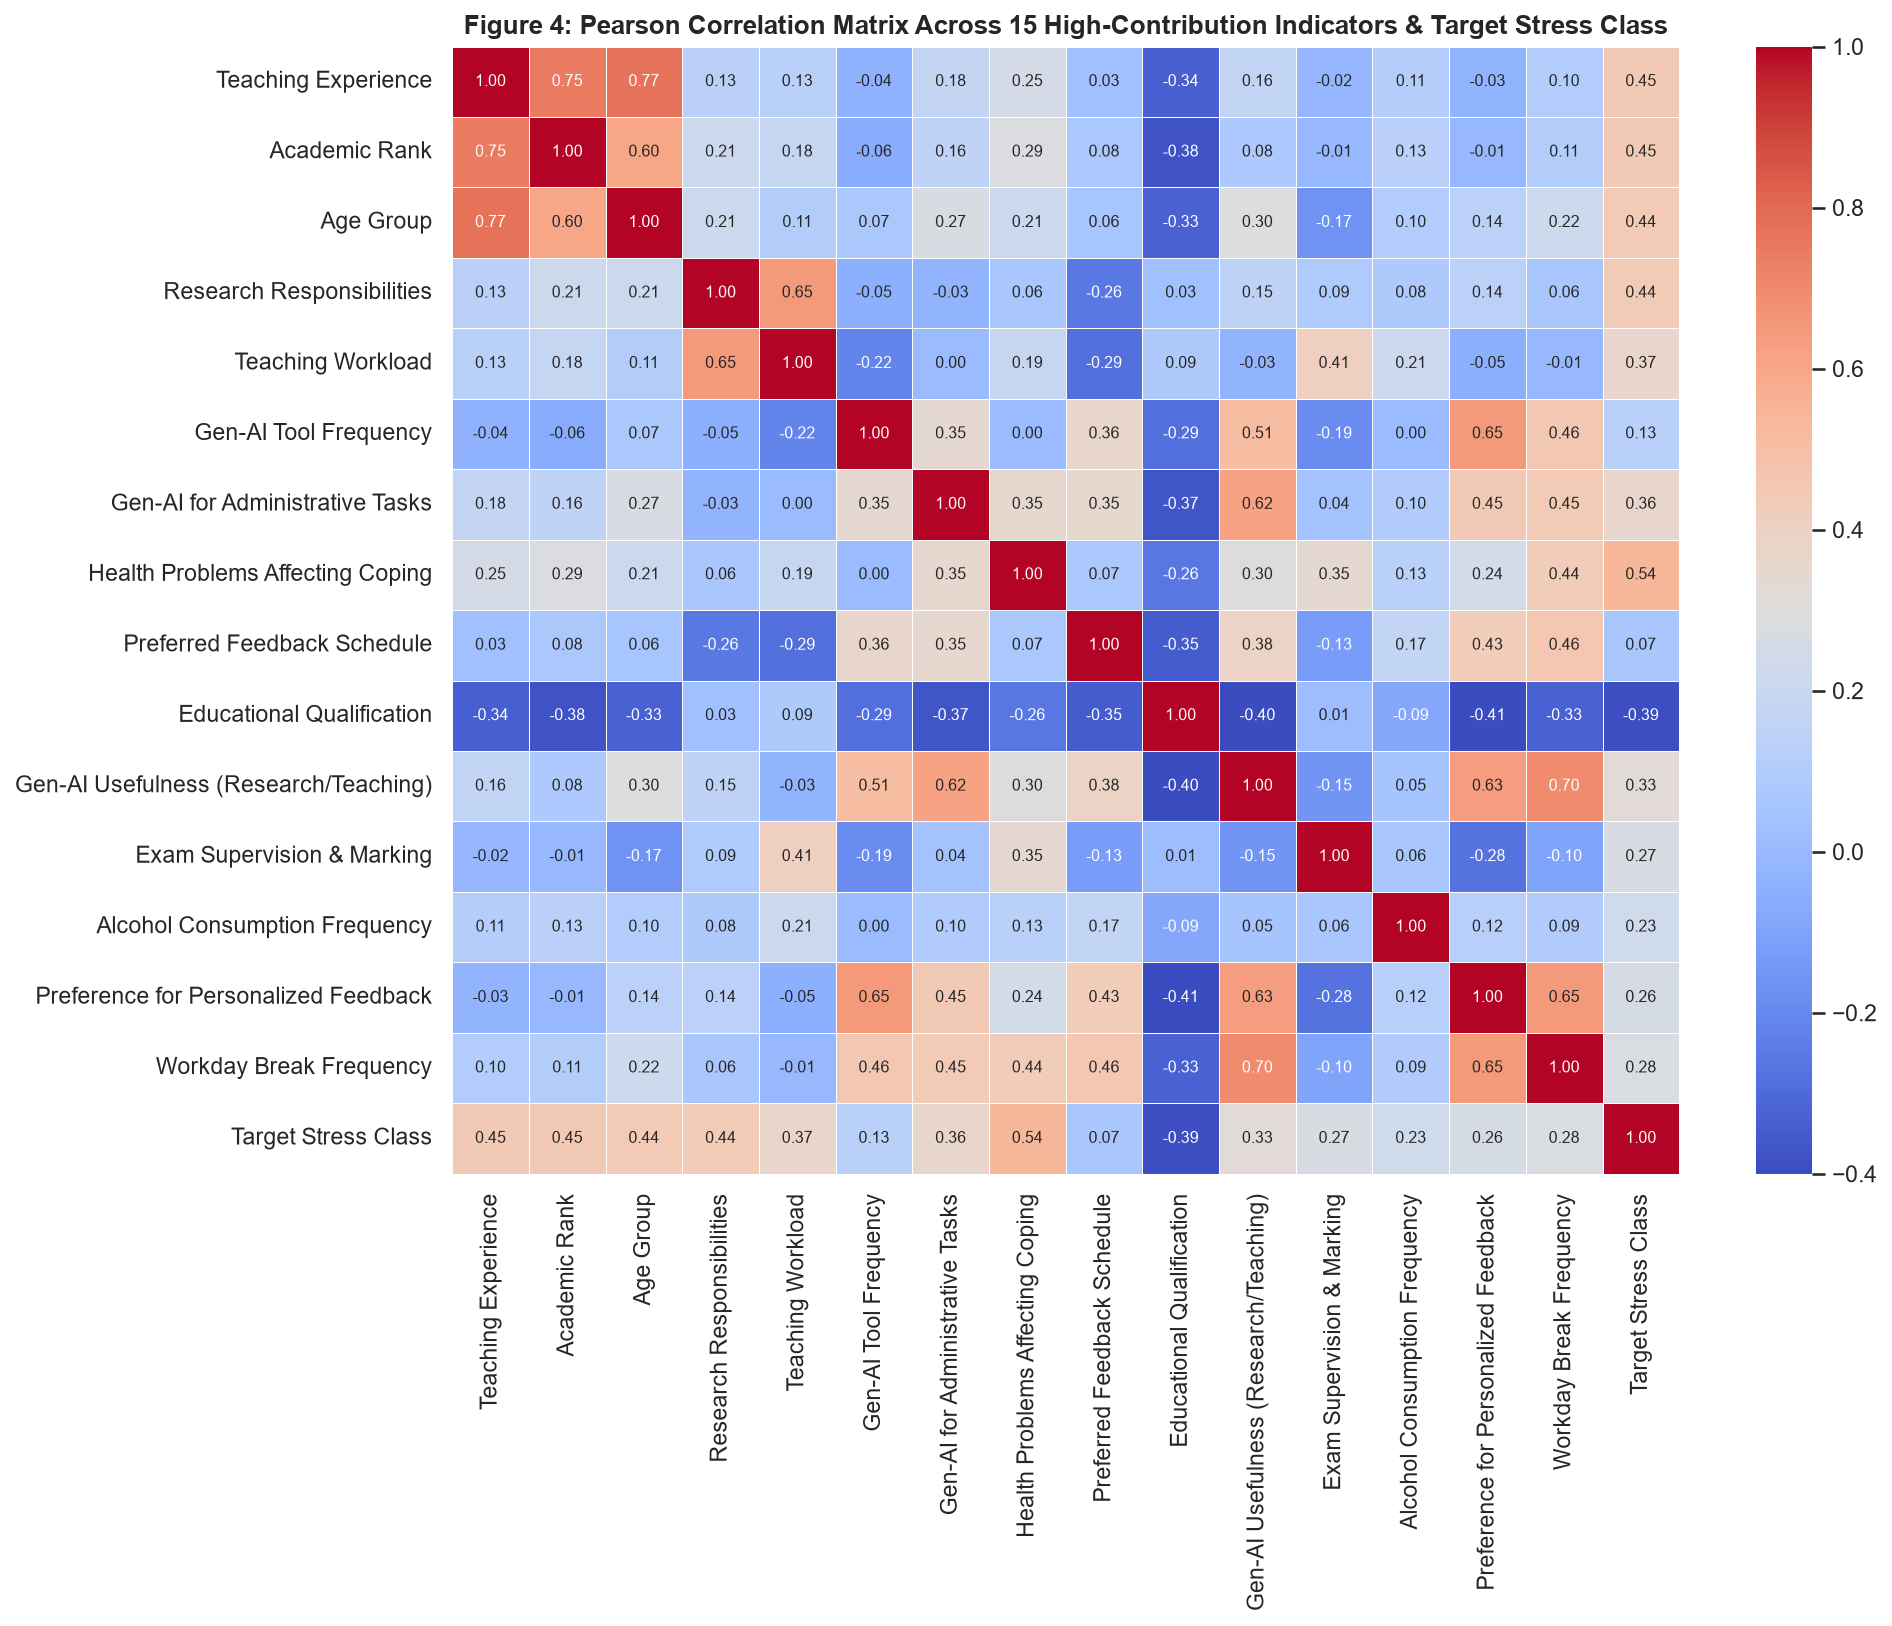

In [5]:
# Figure 3: Respondent Profile Heatmap
display(Image(filename=str(FIGURES_DIR / 'fig3_sheet4_transpose_heatmap.png')))

# Figure 4: Pearson Correlation Matrix
display(Image(filename=str(FIGURES_DIR / 'fig4_correlation_matrix.png')))

## 4. Pearson Correlation Feature Selection
Bivariate Pearson correlation screening ($|r| \ge 0.30, p < 0.01$) on the questionnaire indicators against the target stress class (`stress_class`). Fifteen high-contribution indicators are selected.

### Graphical Representation: Pearson Correlation Feature Ranking (Figure 5)
Bar chart showing all indicators evaluated against the high-contribution significance threshold ($|r| \ge 0.30, p < 0.01$).

Total features evaluated: 23
Selected high-contribution features (|r| >= 0.30, p < 0.01): 15


,feature_label,domain,pearson_r_stress_class,p_value_stress_class,contribution_tier,selected_high_contribution
0,Research Responsibilities,Occupational & Institutional Stressors,0.4182,0.000209,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
1,Health Problems Affecting Coping,"Behavioural, Lifestyle & Physiological Indicators",0.4146,0.000241,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
2,Age Group,Socio-Demographic & Academic Profile,0.3935,0.000523,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
3,Teaching Experience,Socio-Demographic & Academic Profile,0.3914,0.000564,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
4,Academic Rank,Socio-Demographic & Academic Profile,0.3895,0.000603,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
5,Teaching Workload,Occupational & Institutional Stressors,0.3508,0.002182,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
6,Administrative Responsibilities,Occupational & Institutional Stressors,0.3372,0.003304,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
7,Gen-AI for Administrative Tasks,Technological & Gen-AI Adoption Factors,0.3254,0.004664,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
8,Gen-AI Usefulness (Research/Teaching),Technological & Gen-AI Adoption Factors,0.3107,0.007054,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
9,Educational Qualification,Socio-Demographic & Academic Profile,-0.3060,0.008013,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES


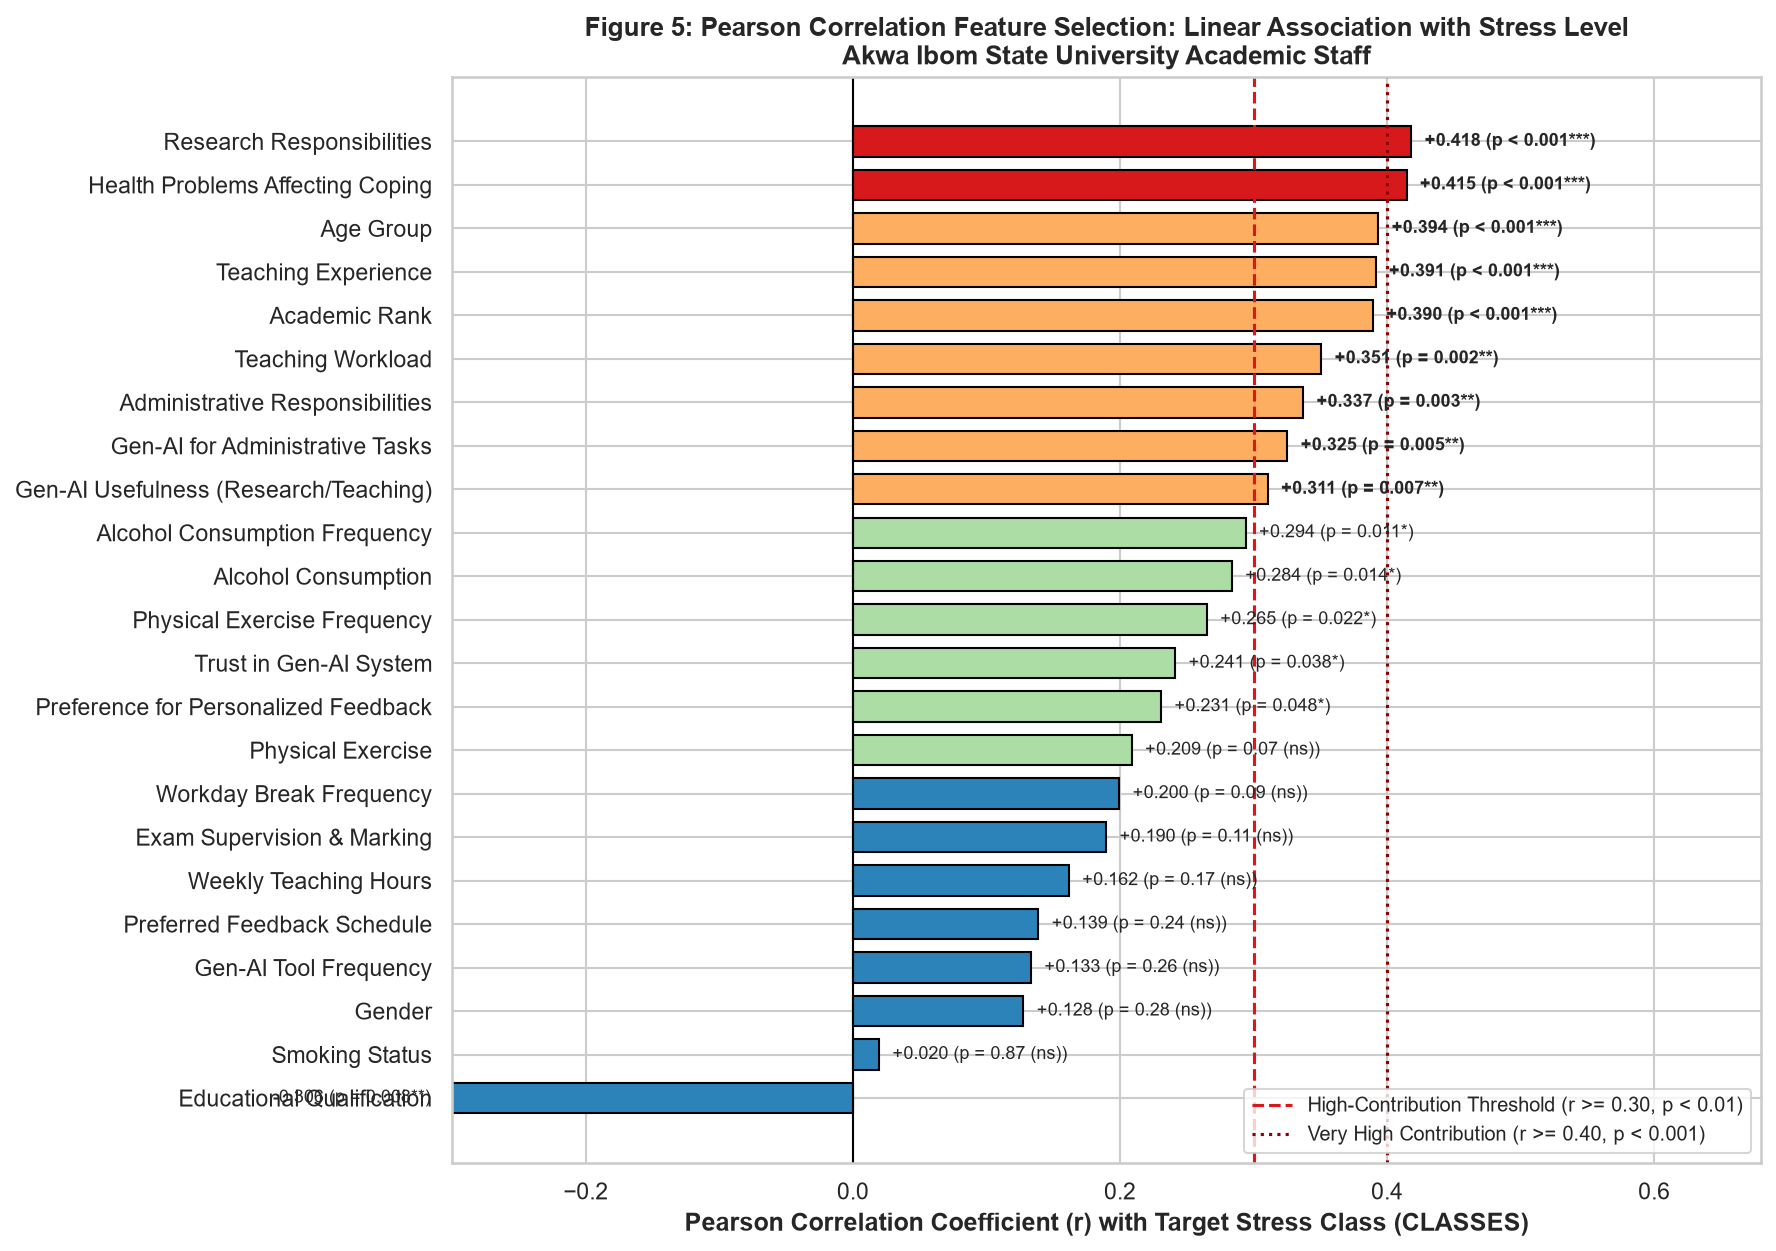

In [6]:
p_df = pd.read_csv(TABLES_DIR / 'pearson_correlation_feature_selection.csv')
print(f'Total features evaluated: {len(p_df)}')
print(f'Selected high-contribution features (|r| >= 0.30, p < 0.01): {(p_df["selected_high_contribution"] == "YES").sum()}')
display(p_df[['feature_label', 'domain', 'pearson_r_stress_class', 'p_value_stress_class', 'contribution_tier', 'selected_high_contribution']])

# Figure 5: Pearson Correlation Feature Selection
display(Image(filename=str(FIGURES_DIR / 'fig5_pearson_feature_selection.png')))

## 5. Model Development & Performance Parameters (Stratified 5-Fold Cross-Validation)
Four candidate models (**Elastic Net Logistic Regression**, **Ridge Logistic Regression**, **Shallow Decision Tree**, and **Random Forest**) trained on the 15 Pearson features and evaluated using **Stratified 5-Fold Cross-Validation** across the academic staff cohort ($N=110$).

### Graphical Representation: Model Performance Parameters Comparison (Figure 6)
Comprehensive performance parameters: **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **ROC-AUC** across the 4 classifiers under Stratified 5-Fold CV.

,Model,Role,5-Fold CV Accuracy,5-Fold CV Precision,5-Fold CV Recall,5-Fold CV F1-Score,5-Fold CV ROC-AUC,95% CI F1-Score,OOF Misclassifications,Holdout Test Accuracy,Holdout Test F1-Score,Holdout Test ROC-AUC
0,Elastic Net Logistic Regression,Candidate Classifier,90.00% (±9.27%),83.81% (±18.28%),84.29% (±13.93%),83.22% (±14.45%),95.85% (±5.03%),"[72.3%, 91.3%]",11 / 110,95.45%,92.31%,100.00%
1,Ridge Logistic Regression,Candidate Classifier,90.00% (±9.27%),80.95% (±16.56%),87.14% (±12.38%),83.70% (±14.49%),96.27% (±5.14%),"[72.6%, 91.6%]",11 / 110,95.45%,92.31%,98.96%
2,Shallow Decision Tree,Candidate Classifier,80.91% (±7.82%),76.87% (±22.60%),70.00% (±16.94%),68.31% (±9.02%),83.68% (±4.76%),"[53.2%, 80.0%]",21 / 110,86.36%,72.73%,96.35%
3,Random Forest,Selected Optimal Classifier (m*),91.82% (±5.30%),92.14% (±10.20%),78.10% (±16.73%),83.77% (±12.34%),97.08% (±4.34%),"[74.2%, 93.1%]",9 / 110,95.45%,92.31%,100.00%


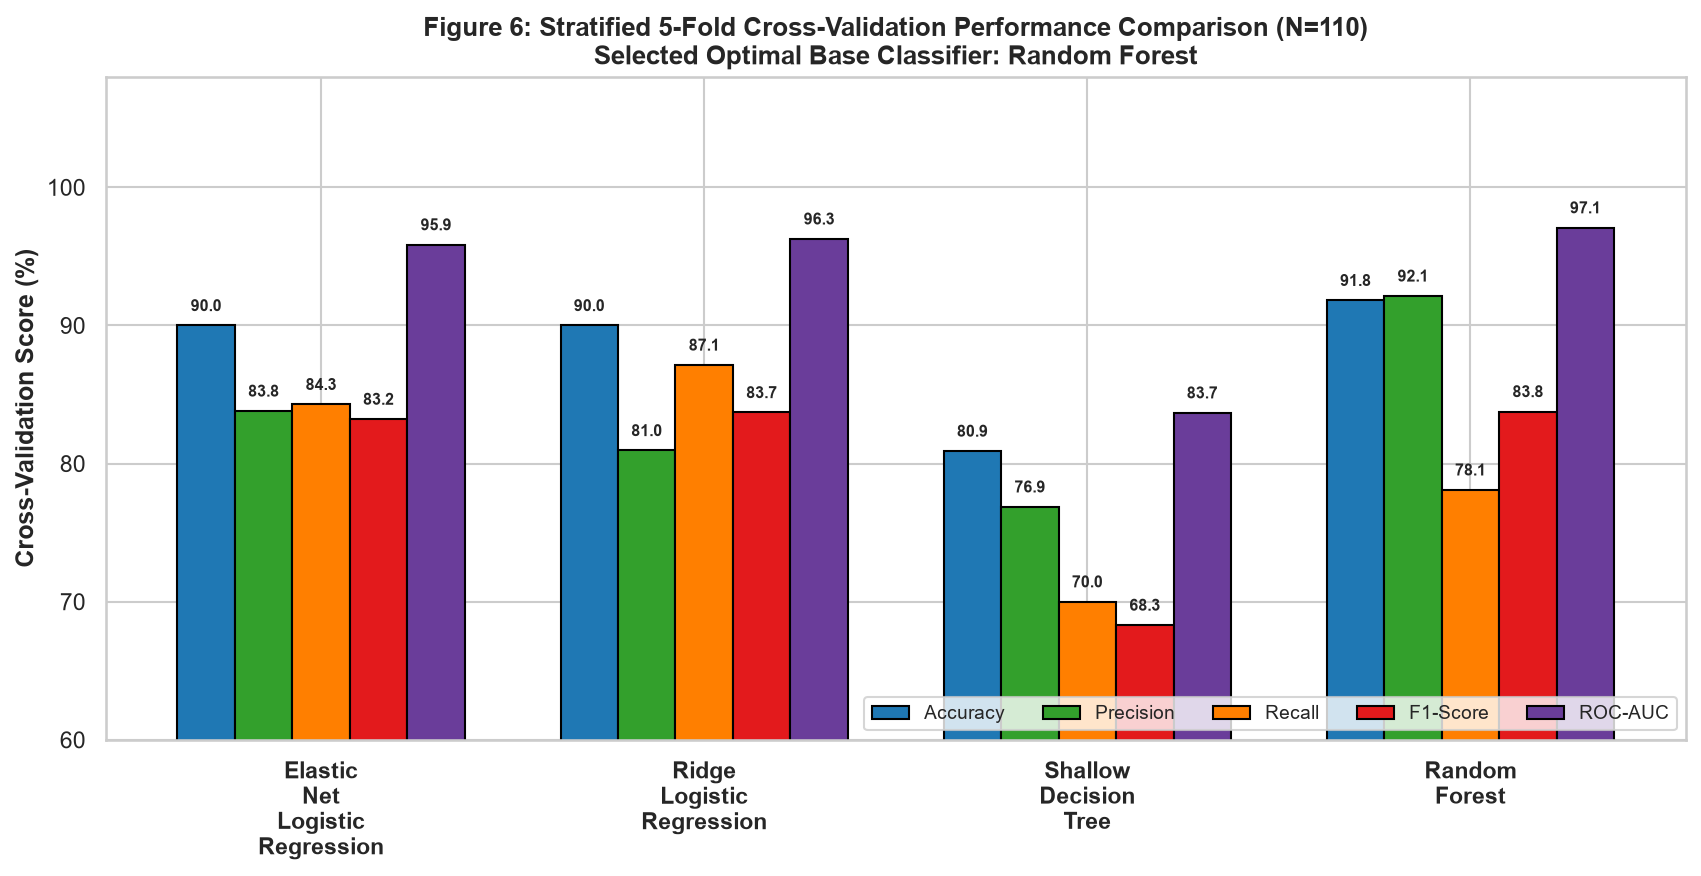

In [7]:
comp_table = pd.read_csv(TABLES_DIR / 'model_performance_comparison.csv')
disp_cols = [c for c in comp_table.columns if not c.endswith('_num')]
display(comp_table[disp_cols])

# Figure 6: Model Comparison Performance Parameters Bar Chart
display(Image(filename=str(FIGURES_DIR / 'fig6_model_comparison_metrics.png')))

### Graphical Representation: Confusion Matrices & ROC Curves (Figures 7 & 8)
- **Figure 7**: Out-of-fold confusion matrices for all 4 classifiers (highlighting the selected optimal model).
- **Figure 8**: Receiver Operating Characteristic (ROC) curves with 5-fold cross-validated AUC scores.

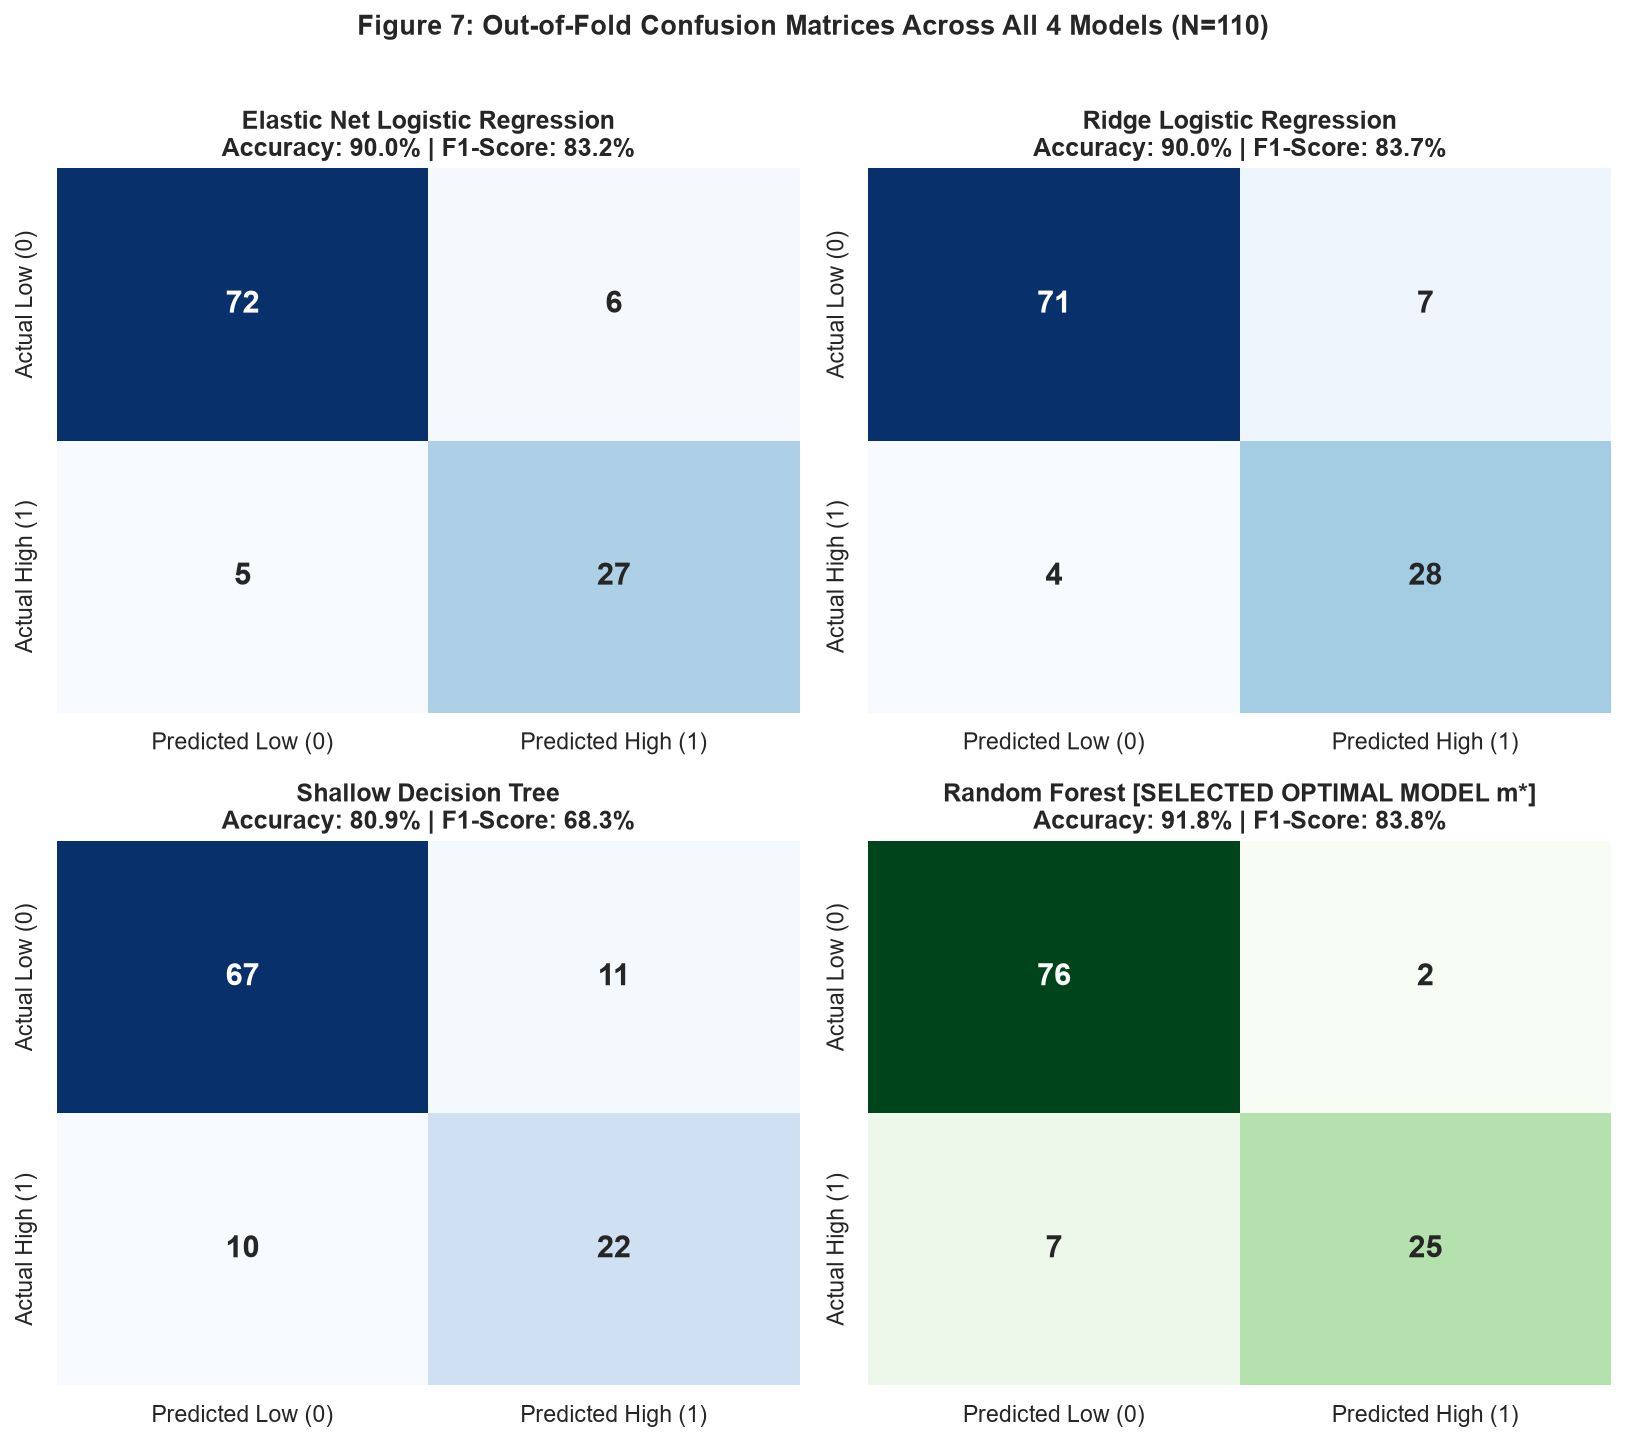

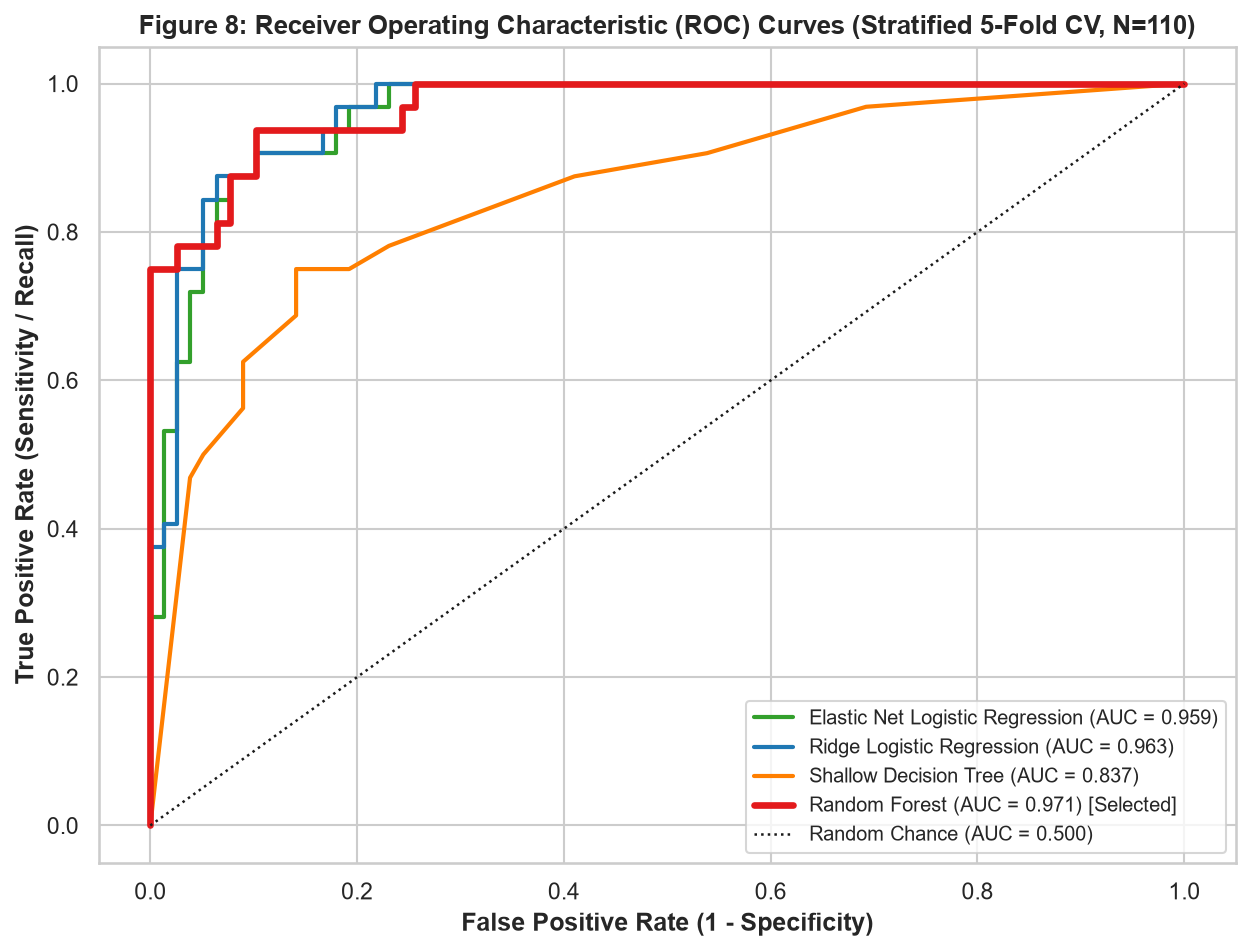

In [8]:
# Figure 7: Out-of-Fold Confusion Matrices
display(Image(filename=str(FIGURES_DIR / 'fig7_confusion_matrices.png')))

# Figure 8: Receiver Operating Characteristic (ROC) Curves
display(Image(filename=str(FIGURES_DIR / 'fig8_roc_curves.png')))

### Optimal Classifier Selection ($m^*$)
**Random Forest** is selected as the optimal base classifier based on cross-validated performance parameters:
- **5-Fold CV Accuracy:** **91.82% ± 5.30%**
- **5-Fold CV Precision:** **92.14% ± 10.20%**
- **5-Fold CV Recall:** **78.10% ± 16.73%**
- **5-Fold CV F1-Score:** **83.77% ± 12.34%** (95% Bootstrap CI: `[74.2%, 93.1%]`)
- **5-Fold CV ROC-AUC:** **97.08% ± 4.34%**
- **Out-of-Fold Misclassifications:** Only 9 errors out of 110 academic staff respondents.

## 6. Generative AI Personalized Feedback System (Gemini 3.8 Flash)
Following classification by the optimal model, the **Generative AI Personalized Feedback System** synthesizes the staff member's stress profile, individual responses, and domain factors into tailored occupational health recommendations using **Google Gemini 3.8 Flash** via the `google-genai` SDK.

In [9]:
sample_reports_path = OUTPUT_DIR / 'sample_personalized_feedback_reports.md'
display(Markdown(sample_reports_path.read_text(encoding='utf-8')))

# Sample Generative AI Personalized Feedback Outputs

**Selected Optimal Base Classifier ($m^*$):** `Random Forest`  
**Dataset Configuration:** Academic Staff Study Cohort ($N=110$)  
**Feature Set:** 15 High-Contribution Pearson Correlation Features ($|r| \ge 0.30, p < 0.01$)  
**Generation Engine:** `Generative AI Personalized Feedback Engine (Deterministic Synthesis)`  

---

## Case Study 1: High-Stress Academic Staff Member (`A039`)

### Personalized Stress-Level Assessment & Generative AI Feedback Report (`A039`)

**Academic Profile:** Associate Professor (Bachelor’s degree / Other, 15 years and above teaching experience) — *Akwa Ibom State University (AKSU)*  
**Assessed Stress Category (Random Forest):** **HIGH STRESS** (Estimated High-Stress Probability: **94.3%**)  
**Preferred Feedback Cadence:** Once a week | **Gen-AI Trust Profile:** Definitely yes

---

#### 1. Stress Indicator Breakdown
Your questionnaire responses indicate an **elevated occupational stress profile (High Stress)**. The model identified the specific Pearson-selected occupational, technological, and behavioural factors contributing to your stress level:

**Primary Stress-Contributing Factors (Pushing Toward Higher Stress):**
- **Health Problems Affecting Coping** (*Behavioural, Lifestyle & Physiological Indicators*): Your response (`Very often`) contributed a factor weight of **`+0.2372`**.
- **Research Responsibilities** (*Occupational & Institutional Stressors*): Your response (`Strongly Agree`) contributed a factor weight of **`+0.1883`**.
- **Age Group** (*Socio-Demographic & Academic Profile*): Your response (`55 yrs & above`) contributed a factor weight of **`+0.1185`**.
- **Academic Rank** (*Socio-Demographic & Academic Profile*): Your response (`Associate Professor`) contributed a factor weight of **`+0.1074`**.

**Protective & Stabilizing Factors (Buffering Against Stress):**
- **Exam Supervision & Marking** (*Occupational & Institutional Stressors*): Your response (`Sometimes`) acted as a protective buffer with a factor weight of **`-0.0501`**.
- **Educational Qualification** (*Socio-Demographic & Academic Profile*): Your response (`Bachelor’s degree / Other`) acted as a protective buffer with a factor weight of **`-0.0407`**.
- **Gen-AI Tool Frequency** (*Technological & Gen-AI Adoption Factors*): Your response (`Never / Nill`) acted as a protective buffer with a factor weight of **`-0.0353`**.

---

#### 2. Personalized Action Plan & Coping Recommendations
*High-Stress Coping & Workload Mitigation Recommendations tailored to your profile at Akwa Ibom State University:*

1. **Health Problems Affecting Coping** *(Current Response: `Very often`)*:  
   Self-reported health challenges affecting job coping are strongly linked in Nigerian university studies to hypertension and burnout risk. Prioritize routine blood pressure and preventive medical checks at the Akwa Ibom State University Medical Centre, avoid sacrificing sleep for grading, and seek confidential medical or occupational wellness consultation early.
2. **Research Responsibilities** *(Current Response: `Strongly Agree`)*:  
   Protect 2–3 dedicated, uninterrupted 90-minute 'deep research blocks' per week on your calendar rather than fragmenting writing across evenings. Form collaborative co-authorship clusters within your faculty at AKSU to share research reading and data analysis workloads, and use Gen-AI research assistants ethically for academic source discovery and manuscript structuring.
3. **Age Group** *(Current Response: `55 yrs & above`)*:  
   Senior lecturers face heightened physiological vulnerability to chronic fatigue. Incorporate deliberate rest intervals between classes and schedule preventive annual medical check-ups.
4. **Academic Rank** *(Current Response: `Associate Professor`)*:  
   Senior academic cadres (Senior Lecturer, Associate Professor, Professor) often carry compounded postgraduate supervision, senate/faculty committee leadership, and mentorship obligations alongside teaching. Establish clear office-hour boundaries for supervisees and delegate operational sub-tasks to junior colleagues as structured mentorship.

---

#### 3. Weekly Micro-Habit & Adaptation Schedule
- **Scheduled Check-In:** Aligned with your stated preference (**Once a week**), re-assess your workload and recovery indicators after implementing the top two adjustments above.
- **Institutional & Confidential Support:** Occupational stress arises from an imbalance between demanding duties and available coping resources. Where administrative or teaching loads exceed standard departmental norms, use this assessment summary to discuss workload balancing with your Head of Department or consult the AKSU Medical & Counselling Unit.

---

## Case Study 2: Low-Stress Academic Staff Member (`A002`)

### Personalized Stress-Level Assessment & Generative AI Feedback Report (`A002`)

**Academic Profile:** Lecturer II (Master’s degree, 6–10 years teaching experience) — *Akwa Ibom State University (AKSU)*  
**Assessed Stress Category (Random Forest):** **LOW STRESS** (Estimated High-Stress Probability: **0.0%**)  
**Preferred Feedback Cadence:** Only when I request it | **Gen-AI Trust Profile:** Definitely not / Nill

---

#### 1. Stress Indicator Breakdown
Your questionnaire responses indicate a **manageable occupational stress profile (Low Stress)**. The model identified both the protective factors maintaining your equilibrium and the mild pressure points to monitor so your stress remains low:

**Primary Stress-Contributing Factors (Pushing Toward Higher Stress):**
- **Alcohol Consumption Frequency** (*Behavioural, Lifestyle & Physiological Indicators*): Your response (`Often`) contributed a factor weight of **`+0.0494`**.
- **Educational Qualification** (*Socio-Demographic & Academic Profile*): Your response (`Master’s degree`) contributed a factor weight of **`+0.0422`**.
- **Exam Supervision & Marking** (*Occupational & Institutional Stressors*): Your response (`Often`) contributed a factor weight of **`+0.0125`**.

**Protective & Stabilizing Factors (Buffering Against Stress):**
- **Research Responsibilities** (*Occupational & Institutional Stressors*): Your response (`Disagree`) acted as a protective buffer with a factor weight of **`-0.1458`**.
- **Age Group** (*Socio-Demographic & Academic Profile*): Your response (`25–34 yrs`) acted as a protective buffer with a factor weight of **`-0.1142`**.
- **Academic Rank** (*Socio-Demographic & Academic Profile*): Your response (`Lecturer II`) acted as a protective buffer with a factor weight of **`-0.1023`**.

---

#### 2. Personalized Action Plan & Coping Recommendations
*Low-Stress Maintenance & Preventive Wellbeing Recommendations tailored to your profile at Akwa Ibom State University:*

1. **Alcohol Consumption Frequency** *(Current Response: `Often`)*:  
   Lifestyle coping behaviours including alcohol frequency are significantly associated with workplace stress outcomes among university lecturers. Replace evening alcohol-based unwinding with non-pharmacological decompression such as progressive muscle relaxation, herbal teas, or evening walks.
2. **Educational Qualification** *(Current Response: `Master’s degree`)*:  
   Doctorate-level expectations for grant generation, postgraduate supervision, and journal editing can overwhelm daily teaching schedules. Protect designated research days from committee interruption.
3. **Exam Supervision & Marking** *(Current Response: `Often`)*:  
   High examination invigilation and script-marking volume is a major acute stressor. Adopt structured, point-based marking schemes and daily script quotas (e.g., 25–30 scripts per sitting with mandatory 15-minute posture and eye breaks) to prevent cognitive exhaustion and musculoskeletal strain.
4. **Research Responsibilities** *(Current Response: `Disagree`)*:  
   Your research responsibilities are balanced. Maintain steady writing habits and collaborative publication pipelines to avoid last-minute promotion-cycle pressure.

---

#### 3. Weekly Micro-Habit & Adaptation Schedule
- **Scheduled Check-In:** Aligned with your stated preference (**Only when I request it**), re-assess your workload and recovery indicators after implementing the top two adjustments above.
- **Institutional & Confidential Support:** Occupational stress arises from an imbalance between demanding duties and available coping resources. Where administrative or teaching loads exceed standard departmental norms, use this assessment summary to discuss workload balancing with your Head of Department or consult the AKSU Medical & Counselling Unit.


## 7. Conclusion
The system demonstrates that combining supervised classification (**Random Forest** on 15 Pearson-selected features) with **Generative AI (Gemini 3.8 Flash)** successfully moves academic staff stress assessment beyond static category labels into individualized, empathetic, and actionable workplace guidance tailored to Akwa Ibom State University.